# 01 — Observation model, observables, their noise, and the design point

> **Notation.** θ = (η, r, v₀) is the vector of the model's parameters: η the amplitude of the angular
> noise, r the interaction radius (the unit of length), v₀ the speed (distance per step). The heading of
> particle i is the angle αᵢ.

## Where we are and why this step exists

[notebook 00](00_simulator.ipynb) gave us a simulator we trust. Inference, however, never sees the simulator: it sees
**data**. Before fitting anything we must decide what the data are, which numbers we compute from them, and
how noisy those numbers are.

**Decided before this notebook**, to resemble a real experiment:
- **Unknown:** θ = (η, r, v₀). **Known:** the box size L, the number of particles N, the noise family (uniform)
  and the sampling interval k.
- **What is observed:** the positions of all particles every k simulation steps (`flockladder.observe`).
  - Headings are **not** observed: a tracking camera sees where the particles are, not where they point.
  - There is no tracking noise yet.
- Every quantity used for inference is computed from those positions only (`flockladder.observables.series`).

**Questions of this notebook:**

| § | question | tool |
|---|---|---|
| 1 | What changes between a sparse and a dense box? | a video, coloured by cluster size |
| 2 | How often should we sample (k)? | heading memory and observables vs k |
| 3 | Which observables, how fast do they settle, how long is their memory? | definitions, relaxation curves, τ |
| 4 | Which observable responds to which parameter, relative to its noise? | sensitivity z at four design points |
| 5 | How many runs does each observable cost? | cost table at the chosen point |
| 6 | What this taught us, and the chosen design point | |



In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from flockladder.animate import animate, show
from flockladder.observables import series, summaries
from flockladder.observe import Observation, observe
from flockladder.results import load, unpack_sensitivity
from flockladder.sensitivity import table
from flockladder.stats import tau_int
from flockladder.vicsek import VicsekParams, box_for_density, simulate

N = 40
L_SPARSE, L_DENSE = box_for_density(N, 0.4), box_for_density(N, 4.0)

## 1. Seeing it: clusters, sparse vs dense

The same noise (η = 2) in two boxes with the same 40 particles:
- a **sparse** box (ρ = 0.4, L = 10), the candidate design point;
- a **dense** box (ρ = 4, L = 3.16), the one used at first in notebook 00.

**How to read the video:**
- **Colour = size of the cluster** each particle belongs to. Two particles are in the same cluster if they
  are linked by a chain of neighbours closer than 1. Purple means alone or in a small group; yellow means
  in a cluster of all 40.
- The linkage distance 1 is a fixed choice of the analyst, in data units. It is *not* the unknown r.
- The black bar is length 1. The dense panel shows a much smaller box, so everything in it looks magnified.
  The arrows have the same length (0.6) in both.

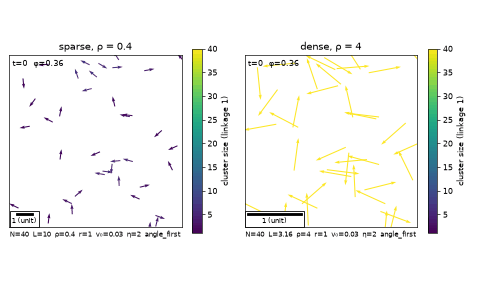

In [2]:
trs = [
    simulate(VicsekParams(eta=2.0, n=N, L=L), 1500, seed=0, record_every=3)
    for L in (L_SPARSE, L_DENSE)
]
gif = animate(
    trs,
    "clusters_sparse_vs_dense",
    color="cluster",
    gif=Path("../figures/clusters_sparse_vs_dense.gif"),
    stride=3,
    fps=15,
    dpi=60,
    titles=["sparse, ρ = 0.4", "dense, ρ = 4"],
)
show(gif)

**How to read this.**
- **Sparse (left):** particles form a mid-size group (teal) plus scattered singles and pairs (purple). The
  groups keep splitting and merging during the video. The counter shows φ ≈ 0.6 at this moment.
- **Dense (right):** every particle is yellow, i.e. the whole flock is **one cluster** at all times. Each
  particle has ~12 neighbours within r.
- **Consequence for inference:** in the dense box the cluster observables are constant (always 1 cluster),
  so they can carry no information. The sparse box has geometry to measure; §4 checks whether that geometry
  actually helps.

## 2. Choosing k — how often to sample positions

**The trade-off:**
- **k = 1** (every step) is almost full observation. The displacement direction *is* the heading, so the
  data would reveal the noise almost directly. That is unrealistic and makes inference nearly trivial.
- **Very large k:** the particle has turned many times between frames, so the displacement no longer
  reflects any single heading, and turning information is lost.
- The right k is **below the heading memory**, i.e. the time over which a particle keeps roughly the same
  direction.

**Method.**
- One long stationary run recorded every step: 20 replicas, 4000 steps after a 5000-step burn-in.
- It is then subsampled at k = 1, 2, 5, 10, 20, 50, 100.
- Left panel: the **heading memory** (this uses the true headings, simulator side only, just to choose k):

$$C_\alpha(\ell) = \big\langle \cos\big(\alpha_i(t+\ell) - \alpha_i(t)\big)\big\rangle_{i,\,t,\,\text{replicas}}$$

  $C_\alpha = 1$ means the heading is unchanged after ℓ steps; 0 means it is forgotten. **The lag ℓ is in
  simulation steps**: this run records every step.
- Right panel: two observables computed from positions sampled every k.
  - The **apparent speed / v₀**: net displacement per step. It equals 1 if particles go straight.
  - The **mean cosine of the turning angle** between consecutive displacements: 1 means no turning.

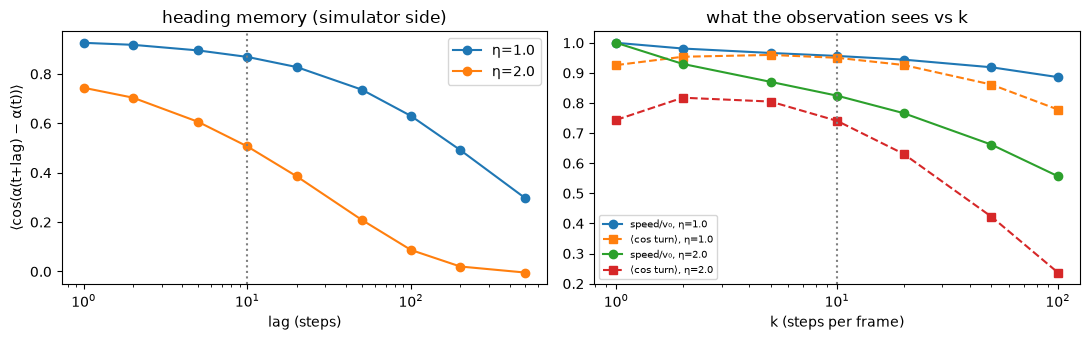

In [3]:
KS = (1, 2, 5, 10, 20, 50, 100)
LAGS = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500])
kscan = {}
for eta in (1.0, 2.0):
    p = VicsekParams(eta=eta, n=N, L=L_SPARSE)
    b = simulate(p, 5000, 20, seed=0, record_every=5000)
    tr = simulate(p, 4000, 20, seed=1, state=(b.pos[-1], b.heading[-1]))
    C = [np.cos(tr.heading[l:] - tr.heading[:-l]).mean() for l in LAGS]
    rows = []
    for k in KS:
        s = series(Observation(tr.pos[::k], k, p.L))
        rows.append((s["speed"].mean() / p.v0, s["cos_turn"].mean(), s["phi"].mean()))
    kscan[eta] = (np.array(C), np.array(rows))

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.5))
for eta, (C, rows) in kscan.items():
    a.semilogx(LAGS, C, "o-", label=f"η={eta}")
    b.semilogx(KS, rows[:, 0], "o-", label=f"speed/v₀, η={eta}")
    b.semilogx(KS, rows[:, 1], "s--", label=f"⟨cos turn⟩, η={eta}")
a.set(
    xlabel="lag (steps)", ylabel="⟨cos(α(t+lag) − α(t))⟩", title="heading memory (simulator side)"
)
b.set(xlabel="k (steps per frame)", title="what the observation sees vs k")
a.axvline(10, c="gray", ls=":")
b.axvline(10, c="gray", ls=":")
a.legend()
b.legend(fontsize=7)
plt.tight_layout()

**How to read this.**
- **Heading memory (left):** at η = 1 (blue) the heading is remembered for a long time: $C_\alpha$ is still
  0.63 after 100 steps and 0.3 after 500. At η = 2 (orange) it is forgotten much faster, ~0.5 after 10 steps
  and ~0.1 after 100. Both curves drop right away at lag 1 (the per-step noise), then decay more slowly
  (the flock slowly changing direction).
- **Apparent speed (right, circles):**
  - It is exactly 1 at k = 1: each step has length v₀.
  - It falls as k grows, because turning shortens the net path: at k = 10 it is 0.96 (η = 1) and 0.82 (η = 2).
  - Here "slow" and "turning a lot" start to look alike. That is the v₀–η confusion, which comes back in notebook 03 and notebook 04.
- **Mean cos turn (right, squares):** it first *rises* from k = 1 to k ≈ 2–5, because the per-step noise
  partly averages out within a frame. It then falls as the heading memory is used up. At k = 100 and
  η = 2 it is down to 0.24: most turning information is gone.

**Choice: k = 10.**
- The net displacement per frame is at most 10 × 0.03 = 0.3r, so particles stay close to their neighbourhood
  between frames.
- k is well within the heading memory at η = 1 and comparable to it at η = 2.
- The departure from full observation is already clear (speed/v₀ = 0.82 at η = 2).
- k = 5 would also be reasonable; k ≥ 50 loses the turning signal at η = 2.

## 3. The observables, their relaxation and memory

### The idea

We want a handful of numbers per frame that capture, from positions alone:
- **how aligned** the motion is (φ, the correlations);
- **how fast and straight** particles move (speed, turning);
- **how the flock is arranged in space** (nearest-neighbour distance, clusters).

Each is averaged over the frames of a run to give one **summary** per run. Inference will compare observed
summaries with simulated ones, so what matters is (a) how each summary responds to the parameters and (b)
how much it fluctuates from run to run. Both are measured in §4.

**Notation.**
- Frames are $t = 0, 1, \dots, T$, one every $k$ simulation steps. $\mathbf{x}_i(t)$ is the observed
  position of particle $i = 1..N$.
- All separations use the minimum-image convention in the periodic box of side $L$:
  $[\mathbf{a}]_L = \mathbf{a} - L\,\mathrm{round}(\mathbf{a}/L)$, componentwise.

$$\Delta_i(t) = [\mathbf{x}_i(t+1) - \mathbf{x}_i(t)]_L, \qquad
\mathbf{u}_i(t) = \frac{\Delta_i(t)}{|\Delta_i(t)|}, \qquad
d_{ij}(t) = \big|[\mathbf{x}_i(t) - \mathbf{x}_j(t)]_L\big|$$

$\mathbf{u}_i$ is the observed direction of motion. It is *not* the heading $\alpha_i$, which is never observed.

**Per-frame observables** (the functions in `flockladder.observables.series`):

$$\varphi(t) = \Big|\frac{1}{N}\sum_i \mathbf{u}_i(t)\Big| \qquad\text{(phi: polarization of displacements)}$$

$$s(t) = \frac{1}{N k}\sum_i |\Delta_i(t)| \qquad\text{(speed: apparent speed, } \le v_0\text{)}$$

$$c(t) = \frac{1}{N}\sum_i \mathbf{u}_i(t+1)\cdot\mathbf{u}_i(t) \qquad\text{(cos\_turn: mean cosine of the turning angle between frames)}$$

$$\bar d(t) = \frac{1}{N}\sum_i \min_{j\ne i} d_{ij}(t) \qquad\text{(nn\_dist)}$$

$$C_{[a,b)}(t) = \frac{\sum_{i\ne j} \mathbf{u}_i(t)\cdot\mathbf{u}_j(t)\ \mathbb{1}[a \le d_{ij}(t) < b]}{\sum_{i\ne j} \mathbb{1}[a \le d_{ij}(t) < b]}
\qquad\text{(corr\_a\_b, bins } [0,1), [1,2), [2,4)\text{)}$$

- **Clusters:** a graph on the particles with an edge $i \sim j$ iff $d_{ij}(t) < \ell$, with $\ell = 1$.
  - `n_clusters` $= $ the number of connected components.
  - `largest_cluster` $= |\text{largest component}| / N$.
- $\ell$ and the correlation bins are fixed by the analyst in data units. They are **not** the unknown
  interaction radius $r$.

**Summaries** (per replica, `flockladder.observables.summaries`): the time average over the $T'$ frames where
each observable is defined. That is $T+1$ for positions, $T$ for displacements and $T-1$ for turning
angles.

$$S_o = \frac{1}{T'}\sum_t o(t), \qquad \chi = N\Big[\overline{\varphi^2} - \overline{\varphi}^{\,2}\Big]
\quad\text{(chi: susceptibility, time variance of } \varphi\text{)}$$

| name | expected to speak to |
|---|---|
| phi, chi | η, r |
| speed | v₀ (and η, through turning) |
| cos_turn | η |
| nn_dist, n_clusters, largest_cluster | geometry, r |
| corr_a_b | r (range of alignment) |

Relaxation from random initial conditions, 20 replicas, 15 000 steps. The integrated autocorrelation
time τ is measured on frames after step 5000.

**Integrated autocorrelation time** (`flockladder.stats.tau_int`). For a stationary series $o(t)$, lag $\ell$ is in
**frames**:

$$\rho(\ell) = \frac{\langle (o(t+\ell)-\bar o)(o(t)-\bar o)\rangle}{\langle (o(t)-\bar o)^2\rangle}, \qquad
\tau = 1 + 2\sum_{\ell=1}^{M}\rho(\ell)$$

The sum is truncated at the first $M \ge 5\tau$ (Sokal's window). τ is the *memory* of the fluctuations,
not their level: a run of $n$ frames holds about $n/\tau$ independent samples. The plots show levels;
the printed table shows τ, in frames of $k = 10$ steps.

observable         τ(η=1)   τ(η=2)   (frames of k=10 steps)
phi                  23.1     14.4
speed                 2.4      2.8
cos_turn              6.4      7.8
nn_dist              71.9     49.0
n_clusters           32.0     38.7
largest_cluster      31.1     26.4
corr_0_1              3.7      3.5
corr_1_2             17.7     16.8
corr_2_4             19.6     10.0


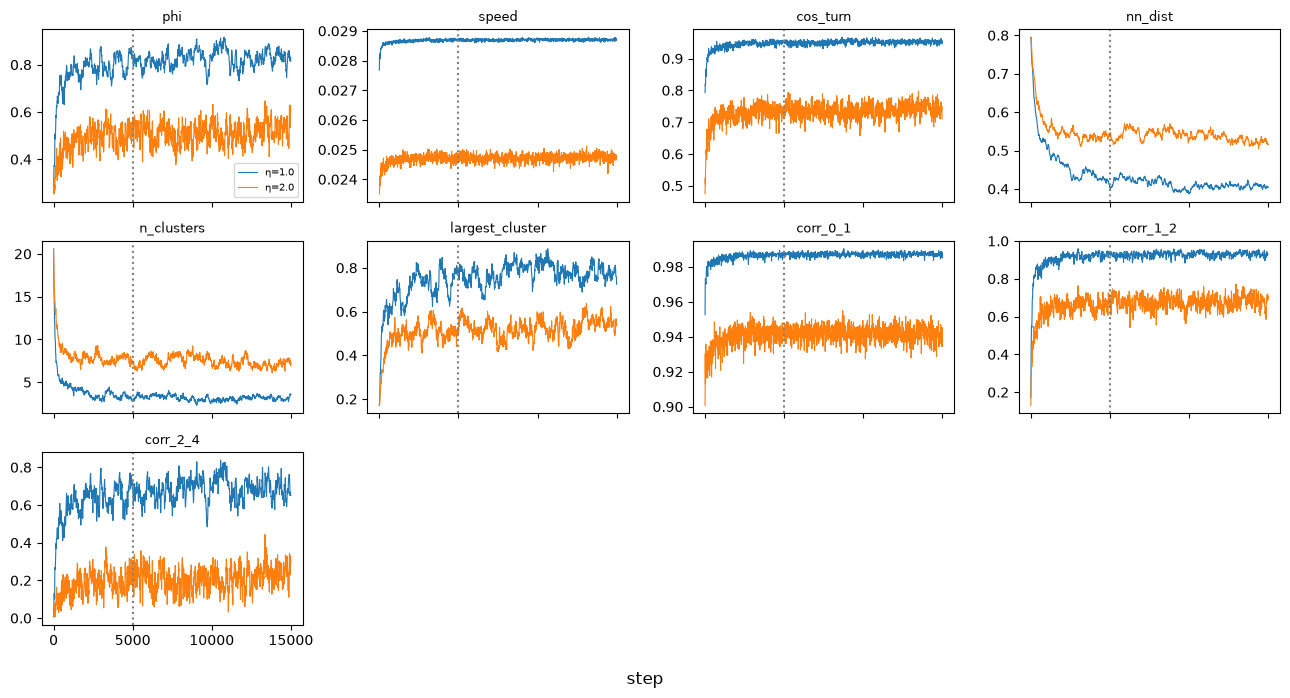

In [4]:
relax, taus = {}, {}
for eta in (1.0, 2.0):
    obs = observe(VicsekParams(eta=eta, n=N, L=L_SPARSE), 1501, 10, n_replicas=20, seed=3)
    relax[eta] = series(obs)
    taus[eta] = {name: tau_int(x[500:]) for name, x in relax[eta].items()}

names = list(relax[1.0])
fig, axes = plt.subplots(3, 4, figsize=(13, 7), sharex=True)
for ax, name in zip(axes.flat, names):
    for eta, s in relax.items():
        ax.plot(10 * np.arange(len(s[name])), s[name].mean(axis=1), lw=0.8, label=f"η={eta}")
    ax.axvline(5000, c="gray", ls=":")
    ax.set_title(name, fontsize=9)
axes.flat[0].legend(fontsize=7)
for ax in axes.flat[len(names) :]:
    ax.axis("off")
fig.supxlabel("step")
plt.tight_layout()

print(f"{'observable':16s} {'τ(η=1)':>8s} {'τ(η=2)':>8s}   (frames of k=10 steps)")
for name in names:
    print(f"{name:16s} {taus[1.0][name]:8.1f} {taus[2.0][name]:8.1f}")

**How to read the curves.** Each panel is one observable, averaged over 20 replicas, from a random start
(step 0) to step 15 000. Blue is η = 1, orange is η = 2. The dotted line at step 5000 is the burn-in used later.
- **Alignment observables** (phi, cos_turn, corr_*) and **speed** jump within the first few hundred steps
  and are flat well before 5000.
- **Geometric observables are slower.** `nn_dist` at η = 1 keeps decreasing until ~8000–10 000 steps: groups
  keep merging, so particles get closer together. The cluster counts settle by ~2000–3000 steps but stay noisy.
- **Two very different stationary levels for η = 1 and 2** in almost every panel: the observables do react to η.

**How to read the τ table.** τ is the memory of each observable's fluctuations, in frames of 10 steps. A run
of 500 frames contains about 500/τ independent measurements.
- **Short memory:** speed (τ ≈ 2.5), corr_0_1 (≈ 3.5) and cos_turn (≈ 7). They are nearly fresh every frame,
  so a run gives ~70–200 independent samples of them.
- **Medium:** phi (14–23), corr_1_2 and corr_2_4 (10–20).
- **Long:** nn_dist (49–72) and the cluster counts (26–39). A 500-frame run gives only ~7–19 independent
  samples of the geometry, so those summaries are the noisiest per run.
- **Memory is longer at η = 1 than at η = 2 for most observables** (less noise means slower-changing
  configurations). The exceptions are speed, cos_turn and n_clusters, which are slightly longer at η = 2.

Recall from §2 that these τ are in **frames**, while the heading-memory lags there were in **steps**.

## 4. Which observable responds to which parameter, relative to its noise?

### The idea

An observable is useful for inferring a parameter if changing the parameter moves it **a lot compared
with how much it fluctuates from run to run anyway**. We measure exactly that ratio.

### Method (`flockladder.sensitivity`)

- For each summary $s$: take a run (5000 burn-in + 5000 measured steps = 501 frames) and its time average.
- Repeat with each parameter changed by ±10%, **using the same random numbers**, so that the difference
  reflects the parameter change, not luck.
- Do this for 40 replicas.

$$z = \frac{0.1\ \partial s/\partial \log\theta}{\text{sd of } s \text{ over one run}}$$

- $z$ is **how many run-to-run standard deviations a 10% change of the parameter moves the summary.**
- $|z| \ge 2$: a single run detects a 10% change.
- $|z| \approx 0$: the summary is blind to that parameter.
- The sign says the direction: positive means the summary increases with the parameter.
- The standard errors of z are ~0.1.

**Four design points:** two densities (ρ = 0.4 sparse, ρ = 4 dense) × two noise levels (η = 1, 2), with
v₀ = 0.03 and r = 1. These 28 runs of 40 replicas take a few minutes, so they are loaded from `results/`;
`scripts/a1_sensitivity.py` regenerates them.

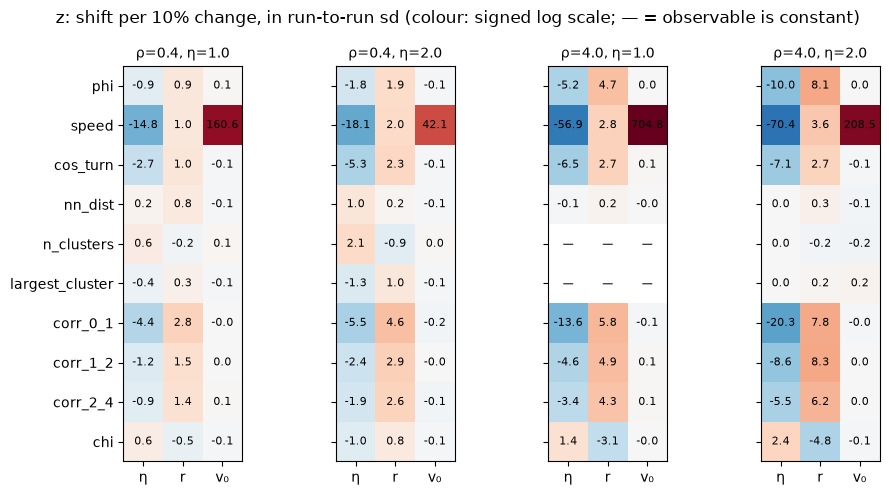

In [5]:
RUN = dict(k=10, n_frames=501, burn_in=5000, n_replicas=40, seed=0)
PARAMS = ("eta", "r", "v0")
points = [(rho, eta) for rho in (0.4, 4.0) for eta in (1.0, 2.0)]
precomputed = load(
    "a1_sensitivity"
)  # scripts/a1_sensitivity.py: sensitivity(p, **RUN) at each point
tables = {
    (rho, eta): table(unpack_sensitivity(f"rho{rho}_eta{eta}", precomputed)) for rho, eta in points
}

obs_names = list(tables[points[0]])
fig, axes = plt.subplots(1, 4, figsize=(10, 5), sharey=True)
for ax, pt in zip(axes, points):
    Z = np.array([[tables[pt][s][f"z_{q}"] for q in PARAMS] for s in obs_names])
    ax.imshow(
        np.sign(Z) * np.log10(1 + np.abs(np.nan_to_num(Z))), cmap="RdBu_r", vmin=-2.5, vmax=2.5
    )
    for i in range(len(obs_names)):
        for j in range(3):
            ax.text(
                j,
                i,
                "—" if np.isnan(Z[i, j]) else f"{Z[i, j]:.1f}",
                ha="center",
                va="center",
                fontsize=8,
            )
    ax.set_xticks(range(3), ["η", "r", "v₀"])
    ax.set_title(f"ρ={pt[0]}, η={pt[1]}", fontsize=10)
axes[0].set_yticks(range(len(obs_names)), obs_names)
fig.suptitle(
    "z: shift per 10% change, in run-to-run sd (colour: signed log scale; — = observable is constant)"
)
plt.tight_layout()

**How to read the heatmaps.** One panel per design point. Rows are summaries, columns are parameters, and
each cell is z. Red is positive, blue is negative, and the colour is on a log scale because z ranges from
0.1 to 700. "—" means the summary is constant at that point, so z is undefined.

- **v₀ column:** only `speed` responds (z = +42 to +705). Every other summary has |z| < 0.25. v₀ is
  determined by one observable.
- **η column:** almost everything responds, with `speed`, `corr_0_1` and `cos_turn` the strongest.
- **r column:** the correlations, φ and cos_turn respond (z ≈ 1–8). In the sparse box, the geometric
  summaries respond weakly.
- **Dense panels (ρ = 4):** the z values are generally *larger*. The fluctuations there are tiny, so small
  responses are easy to see. `n_clusters` and `largest_cluster` are constant ("—" at η = 1, 0 at η = 2).
- **Sparse panels (ρ = 0.4):** the z values are smaller, but more summaries are alive, including the geometric ones.

In [6]:
print(
    "Direction of the η–r effect per observable: z_η / z_r (a ridge means the same ratio everywhere)"
)
print(f"{'observable':16s}" + "".join(f"{f'ρ={r},η={e}':>14s}" for r, e in points))
for s in obs_names:
    cells = []
    for pt in points:
        zr, ze = tables[pt][s]["z_r"], tables[pt][s]["z_eta"]
        ok = np.isfinite(zr) and abs(zr) > 3 * tables[pt][s]["z_r_se"]
        cells.append(f"{ze / zr:14.2f}" if ok else f"{'·':>14s}")
    print(f"{s:16s}" + "".join(cells))

Direction of the η–r effect per observable: z_η / z_r (a ridge means the same ratio everywhere)
observable         ρ=0.4,η=1.0   ρ=0.4,η=2.0   ρ=4.0,η=1.0   ρ=4.0,η=2.0
phi                      -0.90         -0.96         -1.10         -1.23
speed                   -15.38         -8.93        -20.58        -19.35
cos_turn                 -2.58         -2.26         -2.42         -2.69
nn_dist                   0.30             ·             ·             ·
n_clusters                   ·         -2.19             ·             ·
largest_cluster              ·         -1.33             ·             ·
corr_0_1                 -1.56         -1.21         -2.33         -2.60
corr_1_2                 -0.82         -0.81         -0.93         -1.04
corr_2_4                 -0.66         -0.74         -0.81         -0.90
chi                      -1.12         -1.31         -0.45         -0.49


**How to read this table.** For each summary, the ratio z_η / z_r says *in which direction* it responds in the
(η, r) plane. If every summary had the **same** ratio, all of them would respond only to one combination of
η and r, and no set of them could separate the two: a ridge (degeneracy). A "·" means z_r is too small to
give a reliable ratio.

- **phi, chi, corr_1_2, corr_2_4: ratios ≈ −0.5 to −1.3** (chi is the loosest, −0.45 in the dense box). These all respond to roughly the same
  combination. Raising η by 10% and raising r by 10% cancel: more noise offsets a longer alignment range.
  That is the η–r ridge.
- **cos_turn: ≈ −2.3 to −2.7**, and **corr_0_1: −1.2 to −2.6.** They respond more to η relative to r: a
  different direction.
- **nn_dist (+0.3 at ρ = 0.4, η = 1)** and **n_clusters (−2.2 at η = 2)**: other directions again, only
  measurable in the sparse box.
- **speed: −9 to −21.** It is dominated by η (and v₀), almost blind to r.
- So summaries with *different* ratios exist, which means the ridge should be breakable. How well can only
  be judged with their correlations taken into account: that is [notebook 04](04_identifiability.ipynb).

## 5. What does each observable cost? (at the chosen point ρ = 0.4, η = 2)

For inference we need to know how many simulated runs each summary requires. For each summary:
- **mean** and **sd**: its average and run-to-run standard deviation.
- **τ fr**: its memory in frames (from §3).
- **runs ±5%**: how many runs are needed to estimate its mean to ±5% (1 standard error):
  $(\mathrm{sd} / (0.05\,|\mathrm{mean}|))^2$.
- **runs to see 10%**, per parameter: how many runs are needed to detect a 10% change of that parameter at
  2σ, $(2/|z|)^2$, floored at 1. "inf" means the summary does not respond to that parameter.

One replica run is 10 000 steps. Its wall time is measured first.

In [7]:
t0 = time.perf_counter()
_ = summaries(
    series(observe(VicsekParams(eta=2.0, n=N, L=L_SPARSE), 501, 10, 10, seed=99, burn_in=5000)), N
)
per_run = (time.perf_counter() - t0) / 10
print(f"one replica run (10 000 steps + observables): {per_run:.2f} s\n")

T = tables[(0.4, 2.0)]
print(
    f"{'observable':16s} {'mean':>7s} {'sd':>7s} {'τ fr':>6s} {'runs ±5%':>9s}"
    + "".join(f"{'10% ' + q:>9s}" for q in PARAMS)
)
for s in obs_names:
    row = T[s]
    n5 = (row["sd"] / (0.05 * abs(row["mean"]))) ** 2
    need = [
        max(1.0, (2 / abs(row[f"z_{q}"])) ** 2)
        if abs(row[f"z_{q}"]) > 3 * row[f"z_{q}_se"]
        else np.inf
        for q in PARAMS
    ]
    tau = taus[2.0].get(s, np.nan)
    print(
        f"{s:16s} {row['mean']:7.3f} {row['sd']:7.3f} {tau:6.1f} {n5:9.1f}"
        + "".join(f"{n:9.1f}" for n in need)
    )

one replica run (10 000 steps + observables): 0.21 s

observable          mean      sd   τ fr  runs ±5%  10% eta    10% r   10% v0
phi                0.497   0.031   14.4       1.6      1.2      1.1      inf
speed              0.025   0.000    2.8       0.0      1.0      1.0      1.0
cos_turn           0.736   0.012    7.8       0.1      1.0      1.0      inf
nn_dist            0.536   0.026   49.0       1.0      4.0      inf      inf
n_clusters         7.524   0.559   38.7       2.2      1.0      4.5      inf
largest_cluster    0.510   0.042   26.4       2.7      2.5      4.4      inf
corr_0_1           0.942   0.002    3.5       0.0      1.0      1.0      inf
corr_1_2           0.672   0.032   16.8       0.9      1.0      1.0      inf
corr_2_4           0.195   0.037   10.0      14.2      1.1      1.0      inf
chi                1.578   0.149    nan       3.6      3.7      6.4      inf


**How to read this.**
- **A run costs 0.2 s** (10 000 steps plus observables).
- **Single-run summaries:** `speed`, `cos_turn`, `corr_0_1` and `corr_1_2` detect a 10% change in η and
  in r within **one** run. `speed` is the only one that sees v₀, and it too needs one run.
- **Weaker summaries:** `nn_dist`, `largest_cluster` and `chi` need 2.5–6.5 runs for a 10% change, and
  `nn_dist` is blind to r and v₀ here.
- **Estimating the means themselves** is cheap except for `corr_2_4`: it needs 14 runs for ±5%, because its
  mean (0.19) is small compared with its sd (0.037).
- **Caveat:** `speed` is so precise only because there is no tracking noise; real data will change that.

## 6. What this taught us

*Later corrections, recorded here so this notebook is not read in isolation:*
- *"The v₀–η confusion is harmless"* (below) holds for **identifiability** (notebook 04). For **optimisation** it
  matters: it creates the thin curved valley that shapes the search in [notebook 03](03_point_fit.ipynb).
- *"The η–r ridge exists"* holds for the φ-type summaries. With the full summary vector, notebook 04 measured a
  correlation of only +0.76 between the errors in η and r: a tilt, not a ridge.

**k.** k = 10 (net displacement ≤ 0.3r per frame, below the heading memory). Full observation (k = 1) and
coarse sampling (k ≥ 50) are both visibly different regimes.

**Relaxation and memory.**
- **Alignment observables settle fast:** φ, the correlations and cos_turn are stationary by ~2000
  steps. The integrated autocorrelation time τ of φ is 23 frames at η = 1 and 14 at η = 2 (one frame
  = 10 steps).
- **The geometric observables are slower.** `nn_dist` at η = 1 is still drifting down at ~8000–10 000
  steps, and `nn_dist` and the cluster counts have τ ≈ 30–70 frames. The 5000-step burn-in is enough
  for η = 2 but marginal for `nn_dist` at η = 1. If a later step uses the geometry at low η, it needs a
  longer burn-in.

**The dense box was not insensitive to r — a correction to notebook 00.** At ρ = 4, φ moves by ~5 run-sd per
10% of r: *more* than in the sparse box, because the fluctuations there are tiny. What is really dead
in the dense box is the **geometry**: always one cluster, and a flat nearest-neighbour distance. So the
reason to prefer the sparse box is not "r matters there and not here". It is that the sparse box has
**more independent directions of information**, whereas in the dense box every live observable is
some version of "how aligned".

**The v₀–η confusion is real in one observable and harmless overall** (F8).
`speed` mixes the two: at ρ = 0.4 and η = 2, +10% η looks like −4% v₀. But none of φ, cos_turn or the
correlations respond to v₀ at all (|z| < 0.2) at v₀ = 0.03 ≪ r. So the other observables fix η and
`speed` then fixes v₀. Revisit if v₀ is not small compared with r.

**The η–r ridge exists.**
- In φ, χ and the correlations, the ratio z_η / z_r is ≈ −1 at ρ = 0.4, η = 2: a 10% increase in η is
  offset by a 10% increase in r.
- cos_turn (≈ −2.3) and `nn_dist` / `n_clusters` point in other directions. Those are the candidates
  to break the ridge, and that is [notebook 04](04_identifiability.ipynb)'s job, with the proper covariance.

**Design point: N = 40, ρ = 0.4 (L = 10), v₀ = 0.03, η = 2, k = 10.** Reasons:
- φ ≈ 0.5, in the middle of the crossover, not saturated;
- the cluster geometry is alive (7–8 clusters);
- every parameter moves some observable by ≥ 2 run-sd per 10%;
- the ridge is present but not exact.

η = 1 is a reasonable second point (more ordered, fewer clusters).

**Cost.**
- About 0.2 s per replica run (10 000 steps plus observables).
- In a single run, a 10% change of η, r or v₀ is resolved by `speed`, `cos_turn` and `corr_0_1`.
- `nn_dist`, `largest_cluster` and `chi` need 3–6 runs.
- This is the budget the next notebooks start from.
- `speed` is so precise only because there is no tracking noise yet. Expect that to change when noise
  is added.

**Not done:** a scaling check at N = 20 and 80.